# Preprocesamiento de Dataset de Residuos

In [1]:
# Importar librerías necesarias
import os
import cv2
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from google.colab import drive

# Conectar Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Descarga y Extracción
Se extraen las imágenes del archivo ZIP alojado en Google Drive hacia el almacenamiento local de Colab (`/content/drive/MyDrive/Vision - Proyecto/archive.zip`) para acelerar la lectura.

In [2]:
# Definir rutas. ¡Asegúrate de que la ruta del ZIP sea la correcta en tu Drive!
ZIP = "/content/drive/MyDrive/Vision_Proyecto/archive.zip"
DESTINO = Path("/content/drive/MyDrive/Vision_Proyecto")
DESTINO.mkdir(parents=True, exist_ok=True)

# Extraer archivo
print("Extrayendo dataset...")
with zipfile.ZipFile(ZIP) as archivo:
    archivo.extractall(DESTINO)

# Listar imágenes válidas
imagenes = sorted(
    p for p in DESTINO.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)
print("Total de imágenes encontradas:", len(imagenes))
print("Primeras 3 rutas:", imagenes[:3])

Extrayendo dataset...
Total de imágenes encontradas: 15515
Primeras 3 rutas: [PosixPath('/content/drive/MyDrive/Vision_Proyecto/garbage_classification/battery/battery1.jpg'), PosixPath('/content/drive/MyDrive/Vision_Proyecto/garbage_classification/battery/battery10.jpg'), PosixPath('/content/drive/MyDrive/Vision_Proyecto/garbage_classification/battery/battery100.jpg')]


## 2. Análisis del Dataset
Recopilamos metadatos de las imágenes (dimensiones, formato, categoría) e identificamos archivos corruptos.

Analizando imágenes:   0%|          | 0/15515 [00:00<?, ?it/s]


--- Resumen de Estado ---
estado
Correcto    15515
Name: count, dtype: int64


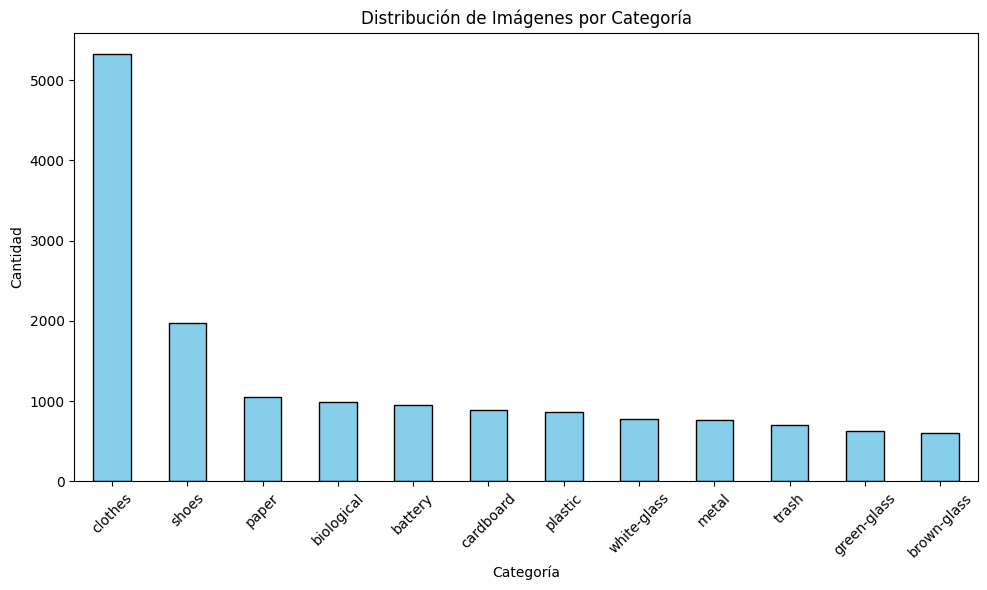

In [3]:
datos = []
for ruta in tqdm(imagenes, desc="Analizando imágenes"):
    img = cv2.imread(str(ruta))

    if img is None:
        datos.append({"archivo": str(ruta.relative_to(DESTINO)), "estado": "Error"})
        continue

    alto, ancho = img.shape[:2]
    datos.append({
        "archivo": str(ruta.relative_to(DESTINO)),
        "categoria_provisional": ruta.parent.name,
        "ancho": ancho,
        "alto": alto,
        "estado": "Correcto"
    })

df = pd.DataFrame(datos)

# Guardar CSV de estadísticas
RESULTADOS = Path("/content/drive/MyDrive/Vision_Proyecto")
RESULTADOS.mkdir(parents=True, exist_ok=True)
df.to_csv(RESULTADOS / "estadisticas_dataset.csv", index=False)

# Mostrar resumen
print("\n--- Resumen de Estado ---")
print(df["estado"].value_counts())

# Graficar distribución de clases (solo las correctas)
df_correctos = df[df["estado"] == "Correcto"]
conteo_clases = df_correctos["categoria_provisional"].value_counts()

plt.figure(figsize=(10, 6))
conteo_clases.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribución de Imágenes por Categoría')
plt.xlabel('Categoría')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar gráfica solicitada
plt.savefig(RESULTADOS / "distribucion_clases.png")
plt.show()

## 3. Redimensionamiento con Padding (256x256)
Evitamos estirar las imágenes agregando bordes de color neutro (114) para mantener la relación de aspecto original.

Procesando imágenes (Padding):   0%|          | 0/15515 [00:00<?, ?it/s]

Imágenes guardadas exitosamente: 15515
Fallidas durante guardado: 0


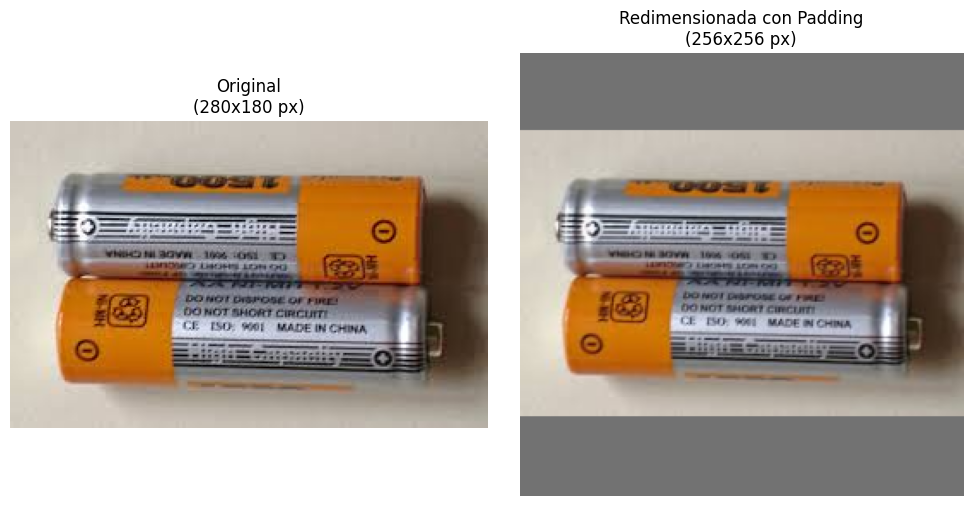

In [4]:
def preparar_imagen(img, tamano=256):
    alto, ancho = img.shape[:2]
    escala = min(tamano / ancho, tamano / alto)

    ancho_nuevo = max(1, round(ancho * escala))
    alto_nuevo = max(1, round(alto * escala))

    reduccion = escala < 1
    img_red = cv2.resize(
        img, (ancho_nuevo, alto_nuevo),
        interpolation=(cv2.INTER_AREA if reduccion else cv2.INTER_LINEAR)
    )

    salida = np.full((tamano, tamano, 3), 114, dtype=np.uint8)
    x = (tamano - ancho_nuevo) // 2
    y = (tamano - alto_nuevo) // 2

    salida[y:y+alto_nuevo, x:x+ancho_nuevo] = img_red
    return salida

PROCESADO = Path("/content/drive/MyDrive/Vision_Proyecto/dataset_procesado")
PROCESADO.mkdir(parents=True, exist_ok=True)
correctas = 0
fallidas = []

for ruta in tqdm(imagenes, desc="Procesando imágenes (Padding)"):
    img = cv2.imread(str(ruta))
    if img is None:
        fallidas.append(str(ruta))
        continue

    resultado = preparar_imagen(img)
    relativa = ruta.relative_to(DESTINO)
    destino = (PROCESADO / relativa).with_suffix(".jpg")
    destino.parent.mkdir(parents=True, exist_ok=True)

    if cv2.imwrite(str(destino), resultado):
        correctas += 1
    else:
        fallidas.append(str(ruta))

print(f"Imágenes guardadas exitosamente: {correctas}")
print(f"Fallidas durante guardado: {len(fallidas)}")

# Tomar la primera imagen válida para la demostración
ruta_prueba = imagenes[0]
img_original = cv2.imread(str(ruta_prueba))
img_original_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB) # Convertir para matplotlib

# Aplicar la función de redimensionamiento con bordes (padding)
img_redimensionada = preparar_imagen(img_original, tamano=256)
img_redimensionada_rgb = cv2.cvtColor(img_redimensionada, cv2.COLOR_BGR2RGB)

# Crear la gráfica comparativa
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(img_original_rgb)
axs[0].set_title(f'Original\n({img_original.shape[1]}x{img_original.shape[0]} px)')
axs[0].axis('off')

axs[1].imshow(img_redimensionada_rgb)
axs[1].set_title(f'Redimensionada con Padding\n(256x256 px)')
axs[1].axis('off')

plt.tight_layout()

# Guardar la imagen para el entregable de GitHub
plt.savefig(RESULTADOS / "comparacion_redimensionamiento.png")
plt.show()

## 4. Comparación de Métodos de Interpolación
Aplicamos diferentes técnicas matemáticas para redimensionar una imagen de muestra y comparamos los resultados visuales.

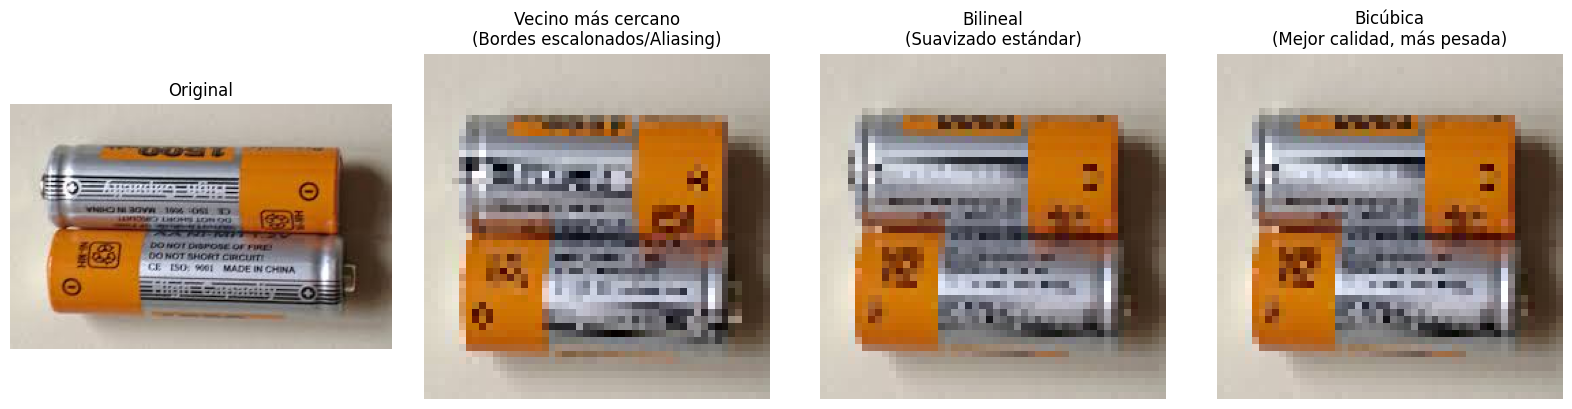

In [5]:
# Tomamos una imagen válida al azar o la primera
img_prueba = cv2.imread(str(imagenes[0]))
img_rgb = cv2.cvtColor(img_prueba, cv2.COLOR_BGR2RGB) # IMPORTANTE para matplotlib

# Redimensionar exageradamente para notar el efecto (ej. a 50x50)
dim = (50, 50)
img_near = cv2.resize(img_rgb, dim, interpolation=cv2.INTER_NEAREST)
img_lin = cv2.resize(img_rgb, dim, interpolation=cv2.INTER_LINEAR)
img_cub = cv2.resize(img_rgb, dim, interpolation=cv2.INTER_CUBIC)

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(img_rgb); axs[0].set_title('Original')
axs[1].imshow(img_near); axs[1].set_title('Vecino más cercano\n(Bordes escalonados/Aliasing)')
axs[2].imshow(img_lin); axs[2].set_title('Bilineal\n(Suavizado estándar)')
axs[3].imshow(img_cub); axs[3].set_title('Bicúbica\n(Mejor calidad, más pesada)')

for ax in axs: ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTADOS / "comparacion_interpolacion.png")
plt.show()

## 5. Transformaciones Geométricas (Afines)
Demostración de Traslación, Rotación y Escalado mediante matrices de transformación.

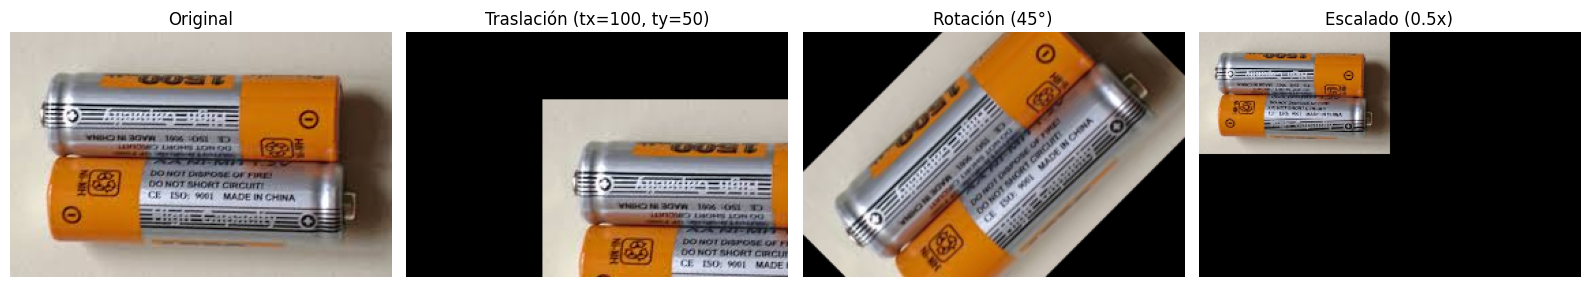

In [6]:
alto, ancho = img_rgb.shape[:2]

# 1. TRASLACIÓN (Mover 100px a la derecha y 50px abajo)
M_traslacion = np.float32([[1, 0, 100], [0, 1, 50]])
img_trasladada = cv2.warpAffine(img_rgb, M_traslacion, (ancho, alto))

# 2. ROTACIÓN (Rotar 45 grados desde el centro, manteniendo escala 1.0)
centro = (ancho // 2, alto // 2)
M_rotacion = cv2.getRotationMatrix2D(centro, 45, 1.0)
img_rotada = cv2.warpAffine(img_rgb, M_rotacion, (ancho, alto))

# 3. ESCALADO (Reducir a la mitad usando WarpAffine)
M_escala = np.float32([[0.5, 0, 0], [0, 0.5, 0]])
img_escalada = cv2.warpAffine(img_rgb, M_escala, (ancho, alto))

# Graficar
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(img_rgb); axs[0].set_title('Original')
axs[1].imshow(img_trasladada); axs[1].set_title('Traslación (tx=100, ty=50)')
axs[2].imshow(img_rotada); axs[2].set_title('Rotación (45°)')
axs[3].imshow(img_escalada); axs[3].set_title('Escalado (0.5x)')

for ax in axs: ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTADOS / "transformaciones_geometricas.png")
plt.show()

## 6. Comprobación y Exportación
Comprimimos los resultados y el dataset procesado para exportarlo de vuelta a Google Drive o descargarlo.

In [7]:
# Comprimir el dataset procesado para enviarlo a Drive
!zip -r /content/drive/MyDrive/Vision_Proyecto/dataset_procesado_final.zip /content/drive/MyDrive/Vision_Proyecto/dataset_procesado

Se truncaron las últimas líneas 5000 del resultado de transmisión.
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper385.jpg (deflated 2%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper386.jpg (deflated 3%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper387.jpg (deflated 3%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper388.jpg (deflated 2%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper389.jpg (deflated 3%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper39.jpg (deflated 3%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classification/paper/paper390.jpg (deflated 1%)
  adding: content/drive/MyDrive/Vision_Proyecto/dataset_procesado/garbage_classi